<!-- d2l:prose id=qlearning-md-1 fw=all -->

# Temporal-Difference Learning

The previous section found the best way across the slippery lake by reading its transition table: for every cell and every command, it summed over the three places the agent might slide to. An agent dropped onto a real lake has no such table. It can only act, see where it lands, and collect whatever reward follows. Each step shows it one successor, chosen by the environment, never the list of possible successors with their probabilities. Can the agent still learn how good each command is, and from that the best policy, from such single draws?

The answer was found by Richard Sutton for predicting values in 1988 and by Chris Watkins for choosing actions in 1989 [@Sutton.1988; @Watkins.1989; @Watkins.Dayan.1992]. Treat the one successor the agent saw as a one-sample estimate of the sum it cannot compute, and move the table entry a small step toward that estimate. Over many visits the steps average the samples, and the average is the backup of dynamic programming. The resulting method, *Q-learning*, needs no model of the environment. With a neural network in place of the table, it becomes the deep Q-learning of the next chapter.

Learning from samples raises two questions. The samples are noisy, so the steps must shrink as visits accumulate; how fast? And an entry for a command the agent never tries is never updated, so the agent must keep trying commands that its table rates poorly. This section answers the first question and meets the second with the simplest rule, acting at random at a small rate; that section studies what that rule costs. The section ends by using the same transitions a second way, to estimate the transition table itself and plan in the estimate.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import gymnasium as gym

<!-- d2l:prose id=qlearning-md-2 fw=all -->

## The Sampled Backup

We start from the equation that value iteration solved and ask which part of it needs the model.

### From the Bellman Operator to One Sample

Value iteration in that section repeated one operation, the Bellman optimality backup. Written for action values instead of state values, the Bellman operator $\mathcal{T}$ maps a table $Q$ to the table

$$
\begin{aligned}
(\mathcal{T}Q)(s, a) &= r(s, a) + \gamma \sum_{s' \in \mathcal{S}} P(s' \mid s, a) \max_{a' \in \mathcal{A}} Q(s', a'), \\
&\quad \textrm{for all } s \in \mathcal{S},\ a \in \mathcal{A}.
\end{aligned}
$$

Each entry of $\mathcal{T}Q$ is the expected immediate reward plus the discounted value of acting greedily on $Q$ from wherever the agent lands. Its fixed point is $Q^*$, and repeated application converges to $Q^*$ from any table, because $\mathcal{T}$ shrinks the largest difference between two tables by the factor $\gamma$, the contraction argument of that section applied to action values.

The model enters the backup in one place, the average over the successor $s'$. An average can be estimated from samples. Suppose the agent stands at $s$, commands $a$, receives reward $r$ and lands in $s'$. The number $r + \gamma \max_{a'} Q(s', a')$ is random. On the lake the reward, too, depends on where the agent lands. Averaged over the successor and the reward, the number equals $(\mathcal{T}Q)(s, a)$. One transition is therefore an unbiased one-sample estimate of one entry of the backup.

This is why model-free control learns $Q$ rather than $V$. The state-value backup $V(s) \leftarrow \max_a [r(s, a) + \gamma \sum_{s'} P(s' \mid s, a) V(s')]$ puts the maximum outside the average over $s'$. One transition shows what one action did and says nothing about the brackets of the other actions, so it cannot estimate their maximum. In the $Q$ form each action has its own entry, the average sits inside that entry, and the maximum acts only on numbers the table already holds. The same form makes the greedy policy $\mathrm{argmax}_a Q(s, a)$ a lookup in one row of the table, again without the model.

Q-learning moves the visited entry a fraction $\alpha$ of the way toward the sample, which is called its *target*:

$$Q(s, a) \leftarrow (1 - \alpha)\, Q(s, a) + \alpha \big( r + \gamma \max_{a'} Q(s', a') \big).$$

The step size $\alpha \in (0, 1]$ says how far to move: $\alpha = 1$ replaces the entry by the target, and a small $\alpha$ averages many targets. Because the target is built from the table's own estimate at the next state, the update is said to *bootstrap*. Rearranged, the change is proportional to a single number,

$$\delta = r + \gamma \max_{a'} Q(s', a') - Q(s, a), \qquad Q(s, a) \leftarrow Q(s, a) + \alpha\, \delta.$$

The number $\delta$ is the *temporal-difference error* [@Sutton.1988]: what the pair appears to be worth one step later, minus what the table said before the step. Panel (d) of the figure draws the substitution. The exact backup sums over every successor; the sampled one follows the single observed transition and keeps the maximum at the next state.

Bootstrapping is a choice. *Monte Carlo* estimation waits until the episode ends and uses the realized return as the target for $Q(s_t, a_t)$. That target is unbiased for the value of the policy that generated the episode, but it carries the randomness of every later transition. A *temporal-difference* target looks one step ahead and trusts the table for the rest. It is biased while the table is inaccurate and usually far less variable [@Sutton.1988; @Sutton.Barto.2018]. Q-learning adds the maximum to the one-step target, and with it estimates $Q^*$ instead of the value of the data-collecting policy.

### One Transition by Hand

Start from a table of zeros on the slippery lake, with $\gamma = 0.95$ and, for easy arithmetic, $\alpha = 0.5$. Every target is zero until the agent first reaches the goal, because rewards are zero elsewhere and every entry it could bootstrap from is zero. Suppose the first success comes from cell $14$, where the command *right* slides into the goal, cell $15$, with probability $1/3$. The goal is terminal, so the target is the reward alone, and

$$Q(14, \textrm{right}) \leftarrow 0.5 \cdot 0 + 0.5 \cdot 1 = 0.5.$$

Nothing else in the table changes. Later the agent stands on cell $13$, commands *right*, and slides to $14$. Its target is $0 + 0.95 \cdot \max_{a'} Q(14, a') = 0.95 \cdot 0.5 = 0.475$, so $Q(13, \textrm{right}) \leftarrow 0.5 \cdot 0.475 \approx 0.24$. Before the update at $14$, the same transition from $13$ would have taught the agent nothing. Value thus flows backward from the goal one cell per visit, along the transitions the agent happens to make. Value iteration moved it one cell per sweep, along all transitions at once.

The targets are noisy. If the agent next commands *right* on $14$ and slips up to cell $10$, whose entries are still zero, the target is $0$ and $Q(14, \textrm{right}) \leftarrow 0.25$. The entry jumps between targets of $1$ and $0$, and later between values bootstrapped from cells $10$ and $14$. Only the average of these targets is the backup, and how fast the step should shrink to form that average is the subject of the step sizes below.

### Least Squares and Double Sampling

Why should such noisy steps lead anywhere? Hold the table fixed and average the temporal-difference error over the successor and the reward:

$$\mathbb{E}[\delta \mid s, a] = (\mathcal{T}Q)(s, a) - Q(s, a).$$

The expected update, $Q(s, a) \leftarrow Q(s, a) + \alpha \big((\mathcal{T}Q)(s, a) - Q(s, a)\big)$, is a damped step of value iteration on that one entry. Q-learning is value iteration executed one sampled entry at a time, each step perturbed by noise of mean zero.

A reader who has fit regression models will object that the natural way to fit a table to targets is least squares. Given $N$ recorded transitions $(s_i, a_i, r_i, s_i')$, we could minimize the squared temporal-difference error by gradient descent,

$$\ell(Q) = \frac{1}{N} \sum_{i=1}^{N} \Big( Q(s_i, a_i) - r_i - \gamma \max_{a'} Q(s_i', a') \Big)^2.$$

The gradient of one term has two parts: one through $Q(s_i, a_i)$, and one through the maximum inside the target. The update the equation keeps the first and drops the second, holding the target fixed. It is therefore called a *semi-gradient* step, and it is not gradient descent on $\ell$.

Dropping the second part is what makes Q-learning correct. Suppose the data contain each pair $(s, a)$ with frequency $d(s, a)$, the visitation distribution of the data-collecting policy, and that there are infinitely many of them. Conditioning on $(s, a)$ splits each expected squared term into the square of its mean and the variance of the target:

$$
\begin{aligned}
L(Q) &= \mathbb{E}_{(s, a) \sim d} \Big[ \big( Q(s, a) - (\mathcal{T}Q)(s, a) \big)^2 \Big] \\
&\quad + \mathbb{E}_{(s, a) \sim d} \Big[ \textrm{Var} \big( r + \gamma \max_{a'} Q(s', a') \bigm| s, a \big) \Big].
\end{aligned}
$$

The first term is the squared Bellman residual and is zero at $Q^*$. The second is the variance of the target over the successor and the reward, and it depends on $Q$ whenever transitions are random. Minimizing $L$ trades a small residual against a less variable target, so its minimizer need not be $Q^*$. Three states show the direction of the distortion. From $s$, the only action leads with probability $1/2$ each to $u_1$, which pays $1$ and terminates, or to $u_2$, which pays $0$ and terminates; so $Q^*(u_1) = 1$, $Q^*(u_2) = 0$ and $Q^*(s) = \gamma/2$. The variance of the target at $s$ is $\gamma^2 (Q(u_1) - Q(u_2))^2/4$, and the minimizer of $L$ lowers it by pulling the two successor values toward each other, away from $1$ and $0$. Exercise 4 computes how far.

Residual-gradient methods descend the full gradient of the squared residual, and they meet the same difficulty [@Baird.1995]. An unbiased estimate of that gradient needs two independent successors of the same pair, one for the target and one for the derivative, and an agent living through one trajectory sees one. This is the *double-sampling problem*. With deterministic transitions and rewards the variance term vanishes and the two approaches agree. Holding the target fixed returns with networks as a second, slowly updated copy of the network that computes the targets, the target network of that section.

### Step Sizes and Convergence

The worked transition showed one entry receiving a stream of noisy targets $y_1, y_2, \ldots$. The plainest way to combine them is to average. With the step size $\alpha_n = 1/n$ at the $n$-th visit of the pair, the update reads $Q_n = Q_{n-1} + (y_n - Q_{n-1})/n = \big((n-1) Q_{n-1} + y_n\big)/n$, and by induction

$$Q_n = \frac{1}{n} \sum_{k=1}^{n} y_k,$$

the sample mean of the targets, whatever the initial value. If the targets were independent draws with a fixed mean, the entry would converge to that mean by the law of large numbers. Robbins and Monro gave conditions under which a decreasing step size has this effect in general [@Robbins.Monro.1951]:

$$\sum_{n=1}^{\infty} \alpha_n = \infty, \qquad \sum_{n=1}^{\infty} \alpha_n^2 < \infty.$$

The first condition lets the steps travel any distance, so the initial value is forgotten. The second makes the accumulated noise finite. The sample mean $\alpha_n = 1/n$ satisfies both. A constant step size violates the second, and its entry keeps fluctuating around the mean with a variance of order $\alpha$ for small $\alpha$.

**Proposition (convergence of tabular Q-learning).** *Let the state and action sets be finite, the rewards bounded and $\gamma < 1$. If every pair $(s, a)$ is updated infinitely often and its step sizes satisfy the Robbins–Monro conditions, then $Q$ converges to $Q^*$ with probability one* [@Watkins.Dayan.1992; @Jaakkola.Jordan.Singh.1994; @Tsitsiklis.1994].

Averaging alone does not prove this, because the targets are computed from the table being learned and have no fixed mean. Residual-gradient descent also has an expected step that vanishes at a fixed point, the wrong one. What singles out Q-learning is the contraction: whatever the current errors, the expected step shrinks the largest of them, and the step-size conditions make the noise around these steps average out.

On calm ice, where every command moves where it says, each pair has one successor and the target carries no transition noise. The update with a constant $\alpha$ is then a damped backup, $Q(s, a) \leftarrow (1 - \alpha) Q(s, a) + \alpha (\mathcal{T}Q)(s, a)$, which applied to all entries contracts with modulus $(1 - \alpha) + \alpha \gamma < 1$. A step as large as $\alpha = 0.9$ is then safe.

The conditions concern the limit, not a finite budget. The sample mean gives every target the same weight, including the early ones computed from a table that was still mostly zero, which on the lake are far too small. With $\alpha_n = 1/n$ the number of updates Q-learning needs can grow exponentially in $1/(1 - \gamma)$, here $20$; with $\alpha_n = 1/n^\omega$ for $1/2 < \omega < 1$ it grows only polynomially [@EvenDar.Mansour.2003]. Below we test $\alpha_n = 1/(1 + n)$, the sample mean with the zero initial value counted as one more target. Our default, $\alpha_n = 1/(1 + 0.1\, n)$, also satisfies both conditions, and its step approaches ten times that of the sample mean. It weights later targets more heavily, the $k$-th one in proportion to about $k^9$ (exercise 5), so the estimate follows the improving targets.

### Terminal Masking

On an episodic task the target needs one correction. A terminal state, here a hole or the goal, has no future, so its continuation value is zero and the target contains only the immediate reward:

$$
\begin{aligned}
Q(s, a) &\leftarrow Q(s, a) \\
&\quad + \alpha \Big( r + \gamma\, \big(1 - \mathbf{1}(s' \textrm{ terminal})\big) \max_{a' \in \mathcal{A}} Q(s', a') - Q(s, a) \Big).
\end{aligned}
$$

The mask uses `terminated`, not `truncated`. As that section explained, a time limit stops the recording at a state from which the process would go on, so its continuation is not zero. Treating truncation as termination would teach the table that the last cell of every long episode is worthless. In code the correction is one factor, `gamma * (1 - terminated) * Q[s_next].max()`.

## Q-Learning on the Slippery Lake

We now run the update on the slippery lake of that section with $\gamma = 0.95$ and grade the result against the exact solution of that section. The learner touches the environment only through `reset` and `step`. The model `mdp`, the optimal values `V_star`, the optimal action values `Q_star` (one backup of $V^*$) and the optimal policy `pi_star` serve only for grading.

In [3]:
gamma, num_episodes, num_seeds = 0.95, 4000, 5
env = gym.make('FrozenLake-v1', is_slippery=True)
mdp = d2l.TabularMDP.from_gym(env, gamma)
V_star = d2l.value_iteration(mdp, num_iters=1000)[-1]
Q_star = mdp.backup(V_star)
pi_star = Q_star.argmax(axis=1)

<!-- d2l:prose id=qlearning-md-3 fw=all -->

### The Behavior Policy

Q-learning needs a rule for choosing actions while it learns, its *behavior policy* $\pi_e$. Acting greedily on the current table fails in two ways. On a table of zeros every row is a four-way tie, and `np.argmax` returns the first index, so a greedy agent would always command *left* and never find the goal. And an action whose entry is currently low is never tried, so its entry is never updated, and the underestimate is permanent. The simplest repair acts at random with a small probability $\epsilon$:

$$\pi_e(a \mid s) = \begin{cases} 1 - \epsilon + \epsilon/|\mathcal{A}| & a = \mathrm{argmax}_{a'} Q(s, a'), \\ \epsilon/|\mathcal{A}| & \textrm{otherwise}. \end{cases}$$

This is the *$\epsilon$-greedy* policy. It explores with probability $\epsilon$ and otherwise takes the greedy action, breaking ties in the argmax uniformly at random. The function draws one uniform number to decide which, then picks a random action or a random member of the set of maximizers:

In [4]:
def epsilon_greedy(q, epsilon, rng):
    """Explore with probability epsilon, else act greedily on the values q."""
    if rng.random() < epsilon:
        return int(rng.integers(len(q)))
    # Ties are coin flips: np.argmax would always pick action 0 on a zero
    # table, and an agent that only ever moves left never finds the goal.
    return int(rng.choice(np.flatnonzero(q == q.max())))

<!-- d2l:prose id=qlearning-md-4 fw=all -->

A table that knows nothing should explore a lot, and a table that is nearly right should mostly exploit. We therefore let $\epsilon$ fall over training. `linear_schedule` turns a start value, an end value and a number of steps into a function of the step that interpolates linearly and then holds the end value:

In [5]:
def linear_schedule(start, end, num_steps):
    """step -> value, interpolated from start to end, then held at end."""
    return lambda step: end + (start - end) * max(0.0, 1.0 - step / num_steps)

<!-- d2l:prose id=qlearning-md-5 fw=all -->

### The Learning Loop

`q_learning` runs the update the equation with the terminal mask. It takes the table `Q` and a table of visit counts `visits`, and changes both in place. The counts set each pair's step size through the function `alpha(n)`, and afterward they record which pairs were tried. The exploration rate is a function `epsilon(k)` of the episode, by default falling from $1$ to $0.05$ over the first half of training and held at $0.05$ after that. The loop body chooses an action, observes one transition, and changes one entry by $\alpha\delta$; the function yields the return of each episode:

In [6]:
def q_learning(seed, Q, visits, env, num_episodes, gamma,
               alpha=lambda n: 1 / (1 + 0.1 * n), epsilon=None):
    """Tabular Q-learning; updates Q in place, yields each episode's return.
    `alpha(n)` is the step size at the n-th visit of a pair; `epsilon(k)` is
    the exploration rate in episode k (default: 1 to 0.05 over the first
    half of the episodes, then held)."""
    rng = np.random.default_rng(seed)
    if epsilon is None:
        epsilon = linear_schedule(1.0, 0.05, num_episodes // 2)
    env.reset(seed=seed)
    for episode in range(num_episodes):
        s, done, ret = env.reset()[0], False, 0.0
        while not done:
            a = epsilon_greedy(Q[s], epsilon(episode), rng)
            s_next, r, terminated, truncated, _ = env.step(a)
            visits[s, a] += 1
            delta = r + gamma * (1 - terminated) * Q[s_next].max() - Q[s, a]
            Q[s, a] += alpha(visits[s, a]) * delta
            s, done, ret = s_next, terminated or truncated, ret + r
        yield ret

<!-- d2l:prose id=qlearning-md-6 fw=all -->

Every cell in this section is plain NumPy, because a table needs only index arithmetic. We train one table per seed for $4{,}000$ episodes and plot the return of each episode:

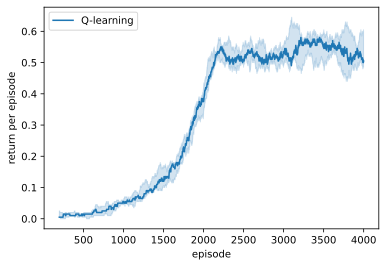

In [7]:
Q = np.zeros((num_seeds, mdp.num_states, mdp.num_actions))
visits = np.zeros_like(Q)
returns = np.array([list(q_learning(k, Q[k], visits[k], env, num_episodes,
                                    gamma)) for k in range(num_seeds)])
d2l.plot_curves({'Q-learning': returns}, xlabel='episode',
                ylabel='return per episode', smooth=200)

<!-- d2l:prose id=qlearning-md-7 fw=all -->

Each point of the curve averages the $200$ episodes that end there, so the curve starts at episode $200$; the band spans the seeds. The return stays near zero while successes are rare, rises as value flows back from the goal, and flattens near $0.5$ after the exploration rate reaches its floor at episode $2{,}000$.

### The Learned Table and the Exact Solution

Is a return near $0.5$ good? The optimal policy of that section reaches the goal within the $100$-step limit about $73\%$ of the time. It maximizes the discounted return, which rewards speed, so a policy that ignores the discount succeeds about one point more often. The training curve, moreover, measures the behavior policy, which still acts at random one step in twenty, so it does not grade the table itself.

Because the model is known here, we can grade the table exactly. With $\gamma = 1$ and a reward of $1$ only at the goal, the value of the start state is the probability of reaching the goal. Run for $100$ sweeps from zero, `policy_evaluation` of that section computes the probability of reaching it within $100$ steps, and `success` wraps this for a policy given as one row of action probabilities per state. The mask `live` marks the cells where the agent acts, and `greedy` holds each table's greedy policy. The cell prints each table's value error and action-value error, the largest value a greedy action gives up under $Q^*$, the exact success rates, the success of $\pi^*$ acting at random with probability $0.05$, and the steps a run used:

In [8]:
lake1 = d2l.TabularMDP.from_gym(env, 1.0)    # gamma = 1: V(s0) = P(goal)
success = lambda pi: d2l.policy_evaluation(lake1, pi, 100)[-1][0]
live = ~np.isin(env.unwrapped.desc.flatten(), [b'H', b'G'])  # agent acts
greedy = np.eye(mdp.num_actions)[Q.argmax(axis=-1)]    # (seed, s, a)
optimal = np.eye(mdp.num_actions)[pi_star]
taxed = 0.95 * optimal + 0.05 / mdp.num_actions        # pi* at epsilon = 0.05
v_err = np.abs(Q.max(axis=-1) - V_star).max(axis=-1)   # one entry per seed
q_err = np.abs(Q - Q_star)[:, live].max(axis=(1, 2))
regret = (V_star - (greedy * Q_star).sum(-1)).max(-1)  # what greedy gives up
wins = [success(g) for g in greedy]
for name, per_seed in [('max_s |V_Qhat(s) - V*(s)|', v_err),
                       ('max_(s,a) |Qhat - Q*|', q_err),
                       ('max_s V*(s) - Q*(s, greedy)', regret),
                       ('greedy success in 100 steps', wins)]:
    print(f'{name:>27}: {np.round(per_seed, 3)}')
steps = np.median(visits.sum(axis=(1, 2)))
print(f'success of pi* {success(optimal):.3f}, of pi* at epsilon = 0.05 '
      f'{success(taxed):.3f}; median environment steps {steps:,.0f}')

  max_s |V_Qhat(s) - V*(s)|: [0.019 0.012 0.021 0.008 0.006]
      max_(s,a) |Qhat - Q*|: [0.131 0.079 0.113 0.087 0.075]
max_s V*(s) - Q*(s, greedy): [0. 0. 0. 0. 0.]
greedy success in 100 steps: [0.73 0.73 0.73 0.73 0.73]
success of pi* 0.730, of pi* at epsilon = 0.05 0.537; median environment steps 95,569


<!-- d2l:prose id=qlearning-md-8 fw=all -->

The third line is zero for every seed: in no cell does a learned greedy action lose value under $Q^*$, so each greedy policy is optimal up to ties and succeeds with the exact $73\%$ of $\pi^*$. This is the typical run, not a guarantee at this budget. In about one run in eight some greedy action is still suboptimal after $4{,}000$ episodes, usually at little cost (success $71\%$ to $74\%$). In the rare worst case the agent still prefers *right* at the start and succeeds less than half the time. The two best actions there differ by less than $0.01$ in $Q^*$, the run's estimates were low, and a low estimate is corrected slowly, because the greedy rule tries that action only when it explores. The value error stays within about $0.03$ of $V^*$ across seeds. The action-value error is several times larger, about $0.05$ to $0.17$: the entries of actions the greedy policy does not take are updated mainly when the agent explores, so they average fewer targets.

Forced to act at random one step in twenty, $\pi^*$ itself succeeds only about $54\%$ of the time. The plateau of the training curve near $0.5$ is this cost of exploration, not a defect of the table.

A run typically uses about $96{,}000$ environment steps. Value iteration certified $V^*$ after $164$ sweeps of $64$ backups, about $10{,}500$ backups, but the two counts measure different things: a backup reads a whole row of the transition table, while a step reveals one sampled successor. Exercise 6 compares the two with these information requirements made explicit.

The learned values and arrows of the first seed, next to the exact solution:

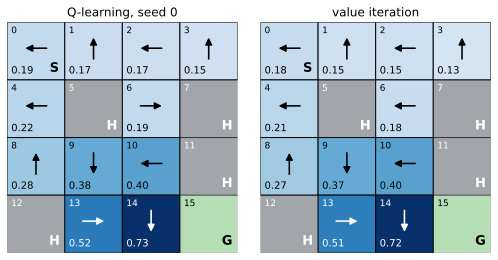

In [9]:
d2l.show_grid(env.unwrapped.desc, np.stack([Q[0].max(-1), V_star]),
              np.stack([Q[0].argmax(-1), pi_star]),
              titles=['Q-learning, seed 0', 'value iteration'])

<!-- d2l:prose id=qlearning-md-9 fw=all -->

The learned arrows reproduce the slip-aware strategy of that section except at cell $6$, where Q-learning commands *right* and $\pi^*$ commands *left*. Cell $6$ lies between the holes $5$ and $7$, and the two commands have equal values under $Q^*$, so the disagreement is a different resolution of an exact tie. The values are most accurate in the cells the agent visits often and coarser in the rarely visited top-right corner.

### Step-Size Schedules Compared

On calm ice the targets carry no transition noise, and the contraction argument above allows the constant step $\alpha = 0.9$. One eighth of the episode budget then almost always suffices, and here the greedy policy of the final table reaches the goal in every episode:

In [10]:
calm = gym.make('FrozenLake-v1', is_slippery=False)
table = np.zeros((mdp.num_states, mdp.num_actions))
calm_visits = np.zeros_like(table)
list(q_learning(0, table, calm_visits, calm, 512, gamma,  # fills table
                alpha=lambda n: 0.9))
print(f'calm ice, 512 episodes ({calm_visits.sum():,.0f} steps), alpha = 0.9: '
      f'greedy policy succeeds '
      f'{d2l.evaluate(calm, lambda s, rng: int(table[s].argmax()), 100):.0%}')

calm ice, 512 episodes (3,658 steps), alpha = 0.9: greedy policy succeeds 100%


<!-- d2l:prose id=qlearning-md-10 fw=all -->

The calm-ice run takes about $3{,}500$ environment steps, against about $96{,}000$ for a run on slippery ice. In the rare run that fails, the agent has reached the goal too seldom for its value to flow back to the start, an exploration failure that that section studies. Transition noise, not the learning rule, sets most of the cost. On slippery ice the step size matters. We compare three schedules on the same seeds by tracking one entry, $Q(s_0, \textrm{left})$, whose exact value $0.180$ is the value of the start under $\pi^*$. The plot shows the median over seeds with a band from the smallest to the largest:

alpha = 0.9 (constant): final estimates [0.056 0.221 0.206 0.265 0.236]


alpha =  1/(1 + 0.1 n): final estimates [0.19  0.186 0.195 0.184 0.18 ]


alpha =      1/(1 + n): final estimates [0.003 0.024 0.008 0.009 0.002]
peak of each 1/(1 + 0.1 n) run:  [0.228 0.291 0.262 0.324 0.205]


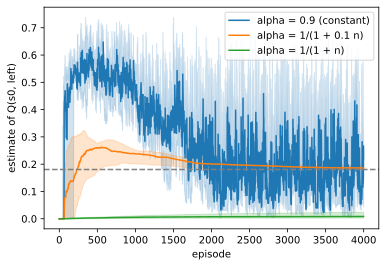

In [11]:
a0 = int(pi_star[0])          # FrozenLake's actions: left, down, right, up
trace = {}
for name, alpha in [('0.9 (constant)', lambda n: 0.9),
                    ('1/(1 + 0.1 n)', lambda n: 1 / (1 + 0.1 * n)),
                    ('1/(1 + n)', lambda n: 1 / (1 + n))]:
    runs = []
    for seed in range(num_seeds):
        Qa = np.zeros_like(Q[0])  # updated in place: read after each episode
        runs.append([Qa[0, a0] for _ in q_learning(
            seed, Qa, np.zeros_like(Qa), env, num_episodes, gamma, alpha)])
    trace[f'alpha = {name}'] = np.array(runs)
    print(f'alpha = {name:>14}: final estimates {np.round(runs, 3)[:, -1]}')
print(f'peak of each 1/(1 + 0.1 n) run:  '
      f'{np.round(trace["alpha = 1/(1 + 0.1 n)"].max(axis=1), 3)}')
d2l.plot_curves(trace, xlabel='episode', ylabel='estimate of Q(s0, left)',
                reference=Q_star[0, a0])

<!-- d2l:prose id=qlearning-md-11 fw=all -->

The constant step never settles. Each target moves the estimate by $90\%$ of its error, so after $4{,}000$ episodes the final estimates scatter widely around $0.180$, from near $0.05$ to above $0.25$. The default schedule ends within about $0.02$ of the exact value in the typical run. The schedule $1/(1 + n)$ satisfies the Robbins–Monro conditions as well, yet every run stays below $0.03$, a sixth of the exact value, at this budget, because the early targets, computed from a table of zeros, keep their full weight. This is the slow rate that Even-Dar and Mansour predict. The conditions guarantee the limit; they do not choose a schedule for a finite budget.

### Feedback between Estimation and Data Collection

The behavior policy depends on the current estimates, so errors in the estimates change which data are collected next. If $Q(s, a)$ is too large, the $\epsilon$-greedy policy selects $a$ more often and gathers transitions whose targets pull the estimate down. If $Q(s, a)$ is too small, the action is tried only when the agent explores, and, as the run above showed, the error is corrected slowly. Overestimates are thus self-correcting and underestimates are not, which is why the low run above took so long to change its first action.

At a fixed point of the update, the expected correction vanishes for every pair the behavior policy visits: $Q(s, a) = (\mathcal{T}Q)(s, a)$ there. This is not yet the optimality equation, because the maximum inside $\mathcal{T}Q$ still ranges over entries that are never visited and hence never constrained. A table can satisfy the equations on the visited pairs and still be wrong, which is why the convergence result needs every pair to be tried. An agent learning from a fixed log of transitions loses this feedback entirely; the next chapter returns to that case.

## Off-Policy Learning

The maximum in the target makes Q-learning learn about one policy while following another. The two subsections below name that property and the bias that comes with it.

### The Off-Policy Target and SARSA

The $\max_{a'}$ in the equation evaluates a greedy continuation regardless of the action the behavior policy takes next at $s'$. Q-learning is therefore *off-policy*: it estimates the values of the greedy policy while the data come from the exploring policy $\pi_e$. The on-policy alternative bootstraps from the action $a'$ that the behavior policy actually selects at $s'$,

$$\delta = r + \gamma\, Q(s', a') - Q(s, a).$$

The method is called *SARSA*, after the tuple $(s, a, r, s', a')$ that each update uses [@Rummery.Niranjan.1994; @Sutton.Barto.2018]. For a fixed behavior policy, the expected SARSA update has the Bellman expectation equation of $\pi_e$ as its fixed point, so SARSA learns $Q^{\pi_e}$, the values of the exploring policy with its random actions included. On the slippery lake, a SARSA agent that keeps $\epsilon = 0.05$ would value the cells next to holes below what $\pi^*$ achieves there, because its own random steps sometimes fall in. Q-learning can explore persistently and still report a greedy policy that agrees with $\pi^*$, as it did above. The same property lets it learn from older experience, from another agent or from a fixed log, as long as the data cover the pairs the greedy policy needs. With networks in place of the table this flexibility can make learning unstable, as the next chapter shows.

### Maximization Bias

The maximum of noisy estimates tends to exceed the maximum of their means, because the maximum picks out the entries whose errors happen to be positive. Since the maximum is convex, $\mathbb{E}[\max_{a'} \hat{Q}(s', a')] \geq \max_{a'} \mathbb{E}[\hat{Q}(s', a')]$, and every target that bootstraps from a noisy row inherits this *maximization bias*. The step-size traces above show it. Under the default schedule, the estimate of $Q(s_0, \textrm{left})$ first climbs above $0.180$ and only then settles. Without noise the estimate could not do this. From a table of zeros, with rewards that are never negative, every exact backup can only raise the values toward $Q^*$, so value iteration approaches $0.180$ from below. The median trace instead sits at about $0.22$ or above from episode $500$ to episode $1{,}500$; noise, passed through the maximum, has pushed it up. The peaks of the printed runs lie between about $0.2$ and $0.33$, and over twelve seeds most runs overshoot in this way, by a few hundredths to more than a tenth. The constant step, whose estimates are noisier, overshoots further, to about $0.5$ for much of the first thousand episodes.

The bias shrinks as the tabular estimates converge, but it can persist under function approximation, where the noise does not vanish. Double Q-learning keeps two estimators, uses one to select the maximizing action and the other to evaluate it, and so removes the upward bias, although its estimates can be low [@vanHasselt.2010]. Exercise 7 builds it on a task where the bias misleads the agent.

## Planning in a Learned Model

Q-learning uses each transition once. It moves one entry and discards the sample, and the next time the goal's value changes, the old transition is not there to carry the change backward. The same transitions can instead be counted. Let $N(s, a, s')$ count the observed transitions from $s$ under $a$ to $s'$, and $N(s, a) = \sum_{s'} N(s, a, s')$. The counts give an estimated model,

$$
\begin{aligned}
\hat{P}(s' \mid s, a) &= \frac{N(s, a, s')}{N(s, a)}, \\
\hat{r}(s, a) &= \frac{1}{N(s, a)} \sum_{\textrm{visits of } (s, a)} r,
\end{aligned}
$$

the empirical frequency of each successor and the mean reward of each pair. Value iteration on $(\hat{P}, \hat{r})$, treating the estimate as if it were exact, is called *certainty equivalence*. It turns the problem without a model back into the problem of that section.

`Counts` wraps an environment: it passes every step through unchanged and records $N(s, a, s')$ and the summed rewards. Since `q_learning` touches the environment only through `reset` and `step`, it runs unchanged on the wrapper and learns the same table as it would without the wrapper. `learned_model` divides the counts into $\hat{P}$ and $\hat{r}$ and returns them as a `d2l.TabularMDP`. Rows of pairs that were never tried stay zero, so the planner treats them as worthless dead ends:

In [12]:
class Counts(gym.Wrapper):
    """Pass every step through and count it: N[s, a, s'] and summed rewards."""
    def __init__(self, env):
        super().__init__(env)
        n_s, n_a = env.observation_space.n, env.action_space.n
        self.N, self.R = np.zeros((n_s, n_a, n_s)), np.zeros((n_s, n_a))

    def reset(self, **kwargs):
        self.s, info = self.env.reset(**kwargs)
        return self.s, info

    def step(self, a):
        s_next, r, terminated, truncated, info = self.env.step(a)
        self.N[self.s, a, s_next] += 1
        self.R[self.s, a] += r
        self.s = s_next
        return s_next, r, terminated, truncated, info

def learned_model(counts, gamma):
    """Certainty equivalence: the empirical kernel and mean rewards."""
    n = np.maximum(counts.N.sum(axis=-1), 1)   # unvisited pairs: zero rows
    return d2l.TabularMDP(counts.N / n[..., None], counts.R / n, gamma)

<!-- d2l:prose id=qlearning-md-12 fw=all -->

How much better is the model's use of the data? We give Q-learning a short budget of $500$ episodes and a longer one of $2{,}000$, each a full run with its own exploration schedule. On the transitions of each run we compare two tables: the one Q-learning learned, and the action values of the estimated model, which are one backup of its value-iteration solution. `grade` returns a table's sup-norm value error against `V_star` and the exact success of its greedy policy, computed by `success`:

In [13]:
def grade(Q, V_star, success):   # sup-norm error, success of greedy policy
    return (np.abs(Q.max(axis=-1) - V_star).max(),
            success(np.eye(Q.shape[-1])[Q.argmax(axis=-1)]))

for budget in [500, 2000]:
    rows = []
    for seed in range(num_seeds):
        counts, Qs = Counts(env), np.zeros((mdp.num_states, mdp.num_actions))
        list(q_learning(seed, Qs, np.zeros_like(Qs), counts, budget,
                        gamma))                    # fills Qs and the counts
        model = learned_model(counts, gamma)
        Q_model = model.backup(d2l.value_iteration(model, 500)[-1])
        rows.append([counts.N.sum(), *grade(Qs, V_star, success),
                     *grade(Q_model, V_star, success)])
    n, err_q, win_q, err_m, win_m = np.median(rows, axis=0)
    print(f'{budget} episodes, median {n:,.0f} steps '
          f'(medians over {num_seeds} seeds)')
    print(f'  Q-learning:        max |V - V*| {err_q:.3f}, success {win_q:.3f}')
    print(f'  planning in model: max |V - V*| {err_m:.3f}, success {win_m:.3f}')

500 episodes, median 9,984 steps (medians over 5 seeds)
  Q-learning:        max |V - V*| 0.084, success 0.486
  planning in model: max |V - V*| 0.096, success 0.639


2000 episodes, median 47,282 steps (medians over 5 seeds)
  Q-learning:        max |V - V*| 0.023, success 0.730
  planning in model: max |V - V*| 0.011, success 0.730


<!-- d2l:prose id=qlearning-md-13 fw=all -->

With little data, about $10{,}000$ steps, the planned greedy policy is the better one. It typically reaches the goal about two times in three, against about one in two for Q-learning's, and it was at least as good in about nine runs out of ten. The worst-case value error at this budget is set by a few rarely visited cells. It is usually smaller for the model, but not always, and the five runs printed here happen to favor Q-learning. With about $47{,}000$ steps both greedy policies are optimal in most runs, and the planned values are about twice as accurate. They were better in nearly every seed, and about as accurate as Q-learning's tables after twice as many episodes. The reason is the one the worked transition showed. Q-learning moves value backward one transition per visit, using targets computed from a table that was wrong when the transition arrived. The model keeps every transition, and each of the few hundred sweeps of value iteration propagates the goal's reward through all of them. Exercise 1 shows the same effect in a two-state process.

The model has costs of its own. It stores $|\mathcal{S}|^2 |\mathcal{A}|$ counts, here about a thousand numbers and for a large state space far too many, and every new batch of data means solving it again. The planner also trusts the estimate completely: a pair that was never tried looks worthless, and a pair that was tried once and got lucky looks better than it is. that section fits such a model on Pendulum with regression in place of counts and plans in it.

The agent can now learn optimal action values from samples alone and act on them, or turn the same samples into a model and plan. Both rest on how it collects data, and the $\epsilon$-greedy rule used here is crude. Forced to act at random one step in twenty, even $\pi^*$ succeeds only about $54\%$ of the time instead of $73\%$, and a greedy table needs a finite set of actions to maximize over. that section asks whether a different rule can learn as much while losing less; later in the chapter the policy itself becomes the object that is learned.

## Summary

Q-learning replaces the expectation in the Bellman backup by one observed transition and moves the visited entry a step $\alpha$ along the temporal-difference error $\delta$. The expected step is a damped value-iteration step, and because the Bellman operator contracts, tabular Q-learning converges to $Q^*$ when every pair is tried infinitely often and the step sizes satisfy the Robbins–Monro conditions. It is a semi-gradient method: gradient descent on the squared temporal-difference error converges elsewhere when transitions are random, the double-sampling problem. On the slippery lake its greedy tables are optimal in the typical run, the step-size schedule decides how fast it gets there, and the maximum in the target makes it off-policy and biases its estimates upward while they are noisy. Counting the same transitions and planning in the estimated model gives more accurate values from the same data, at the cost of storing and solving the model.

## Exercises

1. **Batch TD against Monte Carlo.** A Markov reward process is an MDP
   without actions: each state has a fixed distribution over the reward
   and the successor state. One such process has two
   nonterminal states $x$ and $y$, and $\gamma = 1$. A batch holds eight
   episodes: one moves from $x$ to $y$ with reward $0$ and then terminates
   with reward $0$; six start in $y$ and terminate with reward $1$; one
   starts in $y$ and terminates with reward $0$. TD(0) is the state-value
   form of the equation without the maximum,
   $V(s) \leftarrow V(s) + \alpha \big(r + \gamma V(s') - V(s)\big)$.
    1. Compute the Monte Carlo estimates of $V(x)$ and $V(y)$ from the
       batch, and the values to which TD(0) converges when it replays the
       batch many times with a small step size.
    1. Which pair of estimates has the smaller squared error on the eight
       observed returns?
    1. Estimate the transition probabilities and the expected rewards of
       the process by counting, and solve its Bellman equation exactly.
       Which of the two pairs of estimates does the solution reproduce?
    1. Which pair would you expect to predict the returns of future
       episodes from $x$ better, and under which assumption about the
       process?

    *Adapted from Richard S. Sutton and Andrew G. Barto,
    [Reinforcement Learning: An Introduction](http://incompleteideas.net/book/RLbook2020.pdf),
    Example 6.4.*

1. **Truncation treated as termination.** A task has one state and one
   action, pays reward $1$ at every step, and never terminates. A time
   limit truncates every episode after $H$ steps, as `FrozenLake-v1` does
   after $100$. A faulty implementation masks the bootstrap with
   `terminated or truncated` instead of `terminated`.
    1. With decaying step sizes, the estimate converges to the value at
       which the expected update over the $H$ transitions of an episode
       vanishes. Find this value as a function of $\gamma$ and $H$, and
       compare it with the correct value $1/(1 - \gamma)$ at
       $\gamma = 0.95$ and $H = 100$. Which discount factor does the
       faulty implementation effectively use?
    1. Suppose instead that the time limit is part of the task, so that
       the return really ends after $H$ steps. Show that no single number
       is the correct value of the state. Add the number $h$ of remaining
       steps to the state, as in problem 5
       of that section. Find the value of each state $(s, h)$, and show
       that the mask `terminated or truncated` is then correct.

1. **Greedy SARSA and Q-learning.** SARSA replaces the maximum in
   the equation by the value of the action $a'$ that the behavior
   policy selects at $s'$, as in the equation. An
   implementation selects $a'$ before it updates $Q(s, a)$ and then takes
   $a'$ at the next step. Suppose that both methods select actions
   greedily on their current tables and break ties by the same fixed rule.
   Are SARSA and Q-learning then the same algorithm, making the same action
   selections and the same updates? If they differ, construct a transition
   of the calm lake and table values for which the two methods select
   different actions at the next step.

    *Adapted from Richard S. Sutton and Andrew G. Barto,
    [Reinforcement Learning: An Introduction](http://incompleteideas.net/book/RLbook2020.pdf),
    Exercise 6.12.*

1. [code] **The double-sampling counterexample.** ● Build a three-state
   MDP with one action per state. From state $s$, the action gives reward
   $0$ and moves to $u_1$ or $u_2$ with probability $1/2$ each. From $u_1$,
   it gives reward $1$ and terminates; from $u_2$, it gives reward $0$ and
   terminates. Write $Q(s)$, $Q(u_1)$ and $Q(u_2)$ for the three entries.
    1. Differentiate one term of the sampled objective
       the equation with respect to the table.
       Which entries have nonzero derivatives, and which of these
       derivatives does the semi-gradient update the equation drop?
    1. Write down $Q^*$ for the three entries.
    1. With $d$ uniform over the three pairs, write the population
       objective the equation explicitly and minimize it in
       closed form as a function of $\gamma$. Which entries does the
       minimizer distort relative to $Q^*$, and in which direction?
    1. Visit the three pairs equally often and run, with a decaying step
       size, both the semi-gradient update and stochastic gradient descent
       on the full derivative of part (a). Confirm that each converges to
       the point predicted in parts (b) and (c).
    1. Suppose that the environment can be reset to $s$, so that every
       visit to $s$ yields two independent successors. Use one of them in
       the target and the other in the derivative of part (a). Show that
       the resulting stochastic gradient is unbiased for the gradient of
       the squared Bellman residual, and confirm by simulation that it
       converges to $Q^*$.

1. [code] **Step sizes under a finite budget.** ● The section compares a
   constant step size with schedules $\alpha = 1/(1 + c\, n)$ for
   $c = 0.1$ and $c = 1$, where $n$ counts the visits to the entry,
   including the current one. For the analysis, treat the targets that
   one entry receives as independent draws with mean $m$ and variance
   $\sigma^2$.
    1. For a constant $\alpha$, find the variance of the estimate after
       many updates. Evaluate it at $\alpha = 0.9$ for
       $Q(s_0, \textrm{left})$, taking as targets $r + \gamma V^*(s')$ with
       $s'$ drawn from `mdp.P[0, a0]` and `V_star` from the section, and
       compare the resulting standard deviation with the spread of the
       final constant-step estimates that the section prints around the
       exact value $0.180$. Which assumption of the analysis fails for this
       entry, and where does the rest of the spread come from?
    1. For $c = 1$, write the estimate after $n$ visits as a weighted sum
       of the initial value and the $n$ targets. Which weight does the
       zero initialization receive?
    1. For general $c$, write the weight of the $k$-th target after $n$
       visits as a product, and compare the logarithm of the product with
       an integral to show that the weight grows like $k^{1/c - 1}$ in $k$
       for large $k \leq n$. How does $c = 0.1$ treat the targets that were
       computed from the early, inaccurate table?
    1. Sweep $c \in \{0.01, 0.03, 0.1, 0.3, 1\}$ on the slippery lake,
       five seeds each, and plot against $c$ both the final error
       $|\hat{Q}(s_0, \textrm{left}) - Q^*(s_0, \textrm{left})|$ and the
       sup-norm error $\|\hat{Q} - Q^*\|_\infty$ over all entries. Explain
       the shape of the curves with parts (a) and (c). Do the two error
       measures select the same $c$?

1. [code] **Samples against backups.** ● Take `Q_star` as ground truth.
    1. Record $\|\hat{Q} - Q^*\|_\infty$ after every episode of
       `q_learning` on the slippery lake and plot it against the number of
       environment steps, which the `visits` ledger counts. On the same
       axes, plot the error of value iteration, with $Q_k$ = `mdp.backup`
       of the $k$-th iterate of `d2l.value_iteration`, against the number
       of Bellman backups at $64$ per sweep. How many backups does value
       iteration need to reach the error that Q-learning reaches after
       $4000$ episodes?
    1. Run `q_learning` on `Counts(env)`, and after $100$, $400$, $1000$
       and $4000$ episodes solve `learned_model` with
       `d2l.value_iteration`, as in the section. Add the error of the
       model's action values to the plot at the same environment steps.
       How many environment steps does the model need to reach the error
       of Q-learning after $4000$ episodes, and how many backups does each
       solve of the model cost?
    1. Value iteration consumes model backups, Q-learning consumes
       environment steps, and the estimated model of part (b) consumes
       both. Suppose that one environment step costs as much computation
       as $b$ backups. Using your measurements, find for which range of
       $b$ each of the three methods reaches the error of Q-learning after
       $4000$ episodes at the lowest total cost. Which of the methods
       remain available to an agent that cannot read the transition
       kernel?

1. [code] **Maximization bias in a two-state task.** ● Every episode
   starts in state $s_0$, which offers two actions: *right* terminates with
   reward $0$, and *left* moves to state $s_1$ with reward $0$. In $s_1$,
   each of $m$ actions terminates with a reward drawn from
   $\mathcal{N}(-0.1, 1)$, so *left* is a mistake. Use $\gamma = 1$, the
   constant step size $\alpha = 0.1$, zero initial values, and
   `epsilon_greedy` with $\epsilon = 0.1$.
    1. Implement tabular Q-learning for $m = 10$, and plot against the
       episode index the fraction of runs that take *left* in $s_0$,
       averaged over $1000$ runs of $300$ episodes. What fraction would an
       $\epsilon$-greedy agent acting on $Q^*$ show?
    1. Double Q-learning [@vanHasselt.2010] keeps two tables $Q_1$
       and $Q_2$, acts $\epsilon$-greedily on $Q_1 + Q_2$, and flips a fair
       coin at each transition. On heads it updates
       $$Q_1(s, a) \leftarrow Q_1(s, a) + \alpha \big( r + \gamma\, Q_2(s', \mathrm{argmax}_{a'} Q_1(s', a')) - Q_1(s, a) \big),$$
       and on tails it applies the same update with the two tables
       exchanged. Add its curve to the plot.
    1. Every reward reachable through *left* has a negative mean. Explain
       how Q-learning's estimate of $Q(s_0, \textrm{left})$ nevertheless
       becomes positive. Predict how the Q-learning curve changes for
       $m = 1$ and for $m = 100$, and check. Which part of the effect at
       $m = 100$ comes from noisy estimates, and which from actions that
       have never been tried?

    *Adapted from Richard S. Sutton and Andrew G. Barto,
    [Reinforcement Learning: An Introduction](http://incompleteideas.net/book/RLbook2020.pdf),
    Example 6.7.*

1. [code] **SARSA and Q-learning on the cliff.** ● In `CliffWalking-v1`
   the agent crosses a $4 \times 12$ grid from the bottom-left corner to
   the bottom-right one. Every step costs $-1$, and a step into the cliff
   along the bottom edge costs $-100$ and returns the agent to the start.
   Use $\gamma = 1$, the constant step size $\alpha = 0.5$ and a constant
   $\epsilon = 0.1$.
    1. Write `sarsa`, a copy of `q_learning` that selects the next action
       $a'$ with `d2l.epsilon_greedy` before the update, uses it in the
       target the equation, and then takes it. Train both methods for
       $500$ episodes on ten seeds and plot the return per episode.
    1. Follow the greedy policy of each final table from the start. Which
       path does each method learn, and how long is it? Which method
       collects more reward while it learns, and why do the two answers
       differ?
    1. Let $\epsilon$ fall to zero over training. What happens to the two
       learned paths, and which values does each method learn in the
       limit?

    *Adapted from Richard S. Sutton and Andrew G. Barto,
    [Reinforcement Learning: An Introduction](http://incompleteideas.net/book/RLbook2020.pdf),
    Example 6.6.*

[Discussions](https://d2l.discourse.group/t/36797)